In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import control as ct
#Parámetros del sistema.
R  = 6 #Ω
L  = 3 #mH
Ka = 0.02 #V·s/rad
Km = 0.02 #N·m/A
B  = 5e-5 #N·m·s/rad
J  = 1e-5 #kg·m²



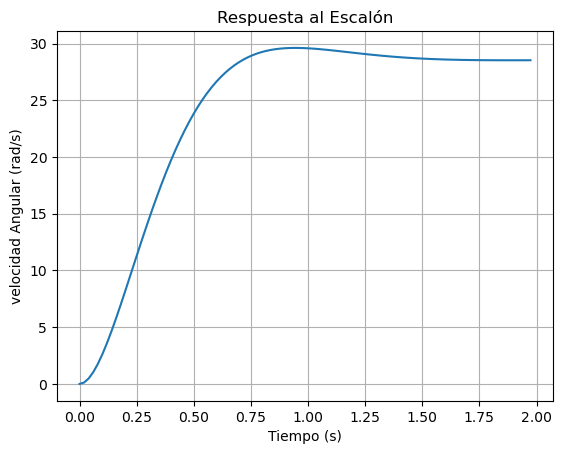

<TransferFunction>: sys[82]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

               0.02
  ------------------------------
  3e-05 s^2 + 0.00021 s + 0.0207
Polos del sistema en lazo cerrado: [-3.5+26.03363209j -3.5-26.03363209j]


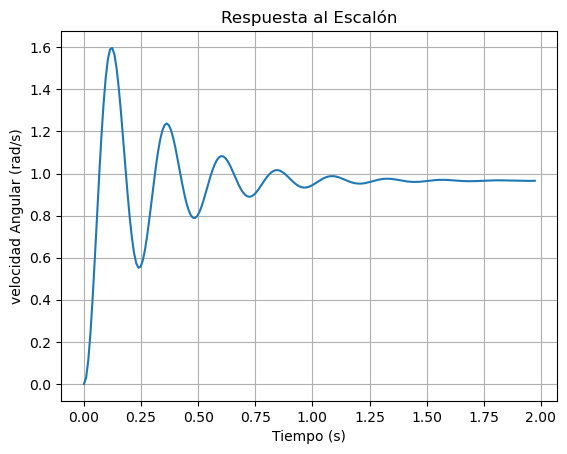

In [20]:
# Función de transferencia
# Función de transferencia del motor DC
GM = ct.tf([Km],[J*L, (B*L + R*J),R*B + Ka*Km])

sal_motor = ct.step_response(GM)
plt.figure()
plt.plot(sal_motor[0], sal_motor[1])
plt.xlabel('Tiempo (s)')
plt.ylabel('velocidad Angular (rad/s)')
plt.title('Respuesta al Escalón')
plt.grid(True)
plt.show()

# Ganancia proporcional
Kp = 1
# Función de transferencia en lazo cerrado
GLC = ct.feedback(Kp*GM,1)
print(GLC)
# Polos del sistema en lazo cerrado
poles = ct.poles(GLC)

wd = np.imag(poles[0])
print("Polos del sistema en lazo cerrado:", poles)
sal = ct.step_response(GLC)
plt.plot(sal[0], sal[1])
plt.xlabel('Tiempo (s)')
plt.ylabel('velocidad Angular (rad/s)')
plt.title('Respuesta al Escalón')
plt.grid(True)
plt.show()


Text(0.5, 0, 'Tiempo (s)')

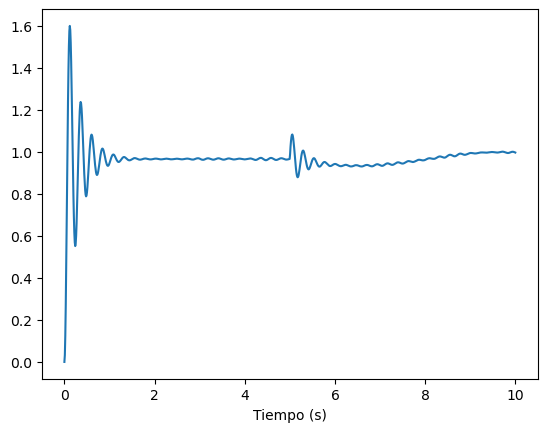

In [18]:
# Solución carga con frecuencia igual a la frecuencia natural del sistema
# Función de voltaje
def vs(t):
    if t < 1:
        return 0
    else:
        return 12

# Par de carga
def TL(t):
    if t < 5:
        return 0
    else:
        return 0.0001*np.sin(wd+1*t)

# velocidad e referencia
w_ref = 1


def motorDC(t,x):
    error = w_ref - x[1]
    vs = Kp*error
    i, w, th = x
    dot_i = (-R*i - Ka*w + vs)/L
    dot_w = (-TL(t) + Km*i - B*w)/J
    dot_th = w
    return np.array([dot_i,dot_w,dot_th])

# Condiciones iniciales
x0 = [0, 0, 0] # i(0), w(0), th(0)

t_eval = np.linspace(0, 10, 1000)
sol = solve_ivp(motorDC, [0, 10], x0, t_eval=t_eval)
plt.plot(sol.t, sol.y[1])
plt.xlabel('Tiempo (s)')




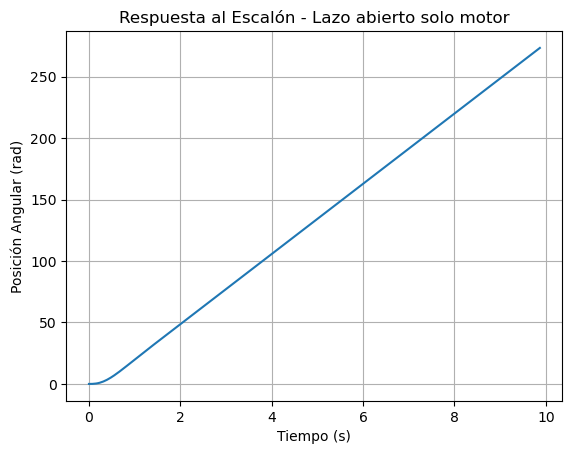

<TransferFunction>: sys[121]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                    0.002
  ------------------------------------------
  3e-05 s^3 + 0.00021 s^2 + 0.0007 s + 0.002
Polos del sistema en lazo cerrado: [-5.+0.j         -1.+3.51188458j -1.-3.51188458j]


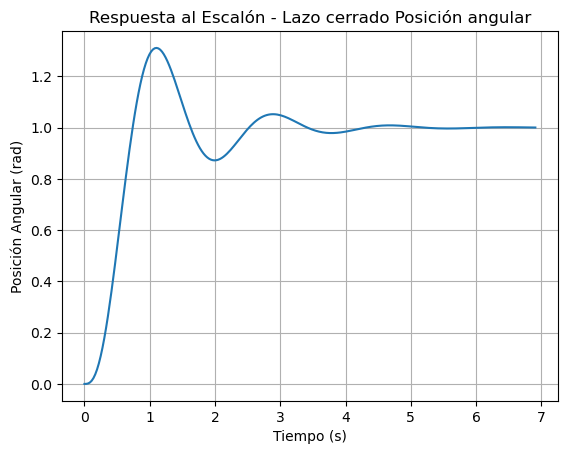

In [23]:
# Control de posición angular
# Función de transferencia del motor DC
GM_pos = ct.tf([Km],[J*L, (B*L + R*J),R*B + Ka*Km, 0])
sal_motor_pos = ct.step_response(GM_pos)
plt.figure()
plt.plot(sal_motor_pos[0], sal_motor_pos[1])
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición Angular (rad)')
plt.title('Respuesta al Escalón - Lazo abierto solo motor')
plt.grid(True)
plt.show()

Kp = 0.1
# Función de transferencia en lazo cerrado
GLC_pos = ct.feedback(Kp*GM_pos,1)
print(GLC_pos)
# polos de lazo cerrado
poles_pos = ct.poles(GLC_pos)
print("Polos del sistema en lazo cerrado:", poles_pos)
sal_pos = ct.step_response(GLC_pos)
plt.figure()
plt.plot(sal_pos[0], sal_pos[1])
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición Angular (rad)')
plt.title('Respuesta al Escalón - Lazo cerrado Posición angular')
plt.grid(True)
plt.show()



# 